### 1. Mount Google Drive

Run the cell below. It will prompt you for permission to access your Google Drive files.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


###Load and Clean the Real Data

In [ ]:
import pandas as pd
import numpy as np

# 1. Load DHB Data (Real SA Clinic Availability)
dhb_path = '/content/drive/MyDrive/DATA/dhb_2018_19/tracer_medicines_available.csv'
dhb = pd.read_csv(dhb_path)

# Clean column names (lowercase, remove spaces)
dhb.columns = dhb.columns.str.lower().str.replace(' ', '_')

# We need to find the column that contains the percentage values.
# It usually has 'percentage' or 'tracer' in the name.
# Let's assume the last column is the percentage of facilities with medicines available.
pct_col = [col for col in dhb.columns if 'percentage' in col or '90' in col][0]
dhb_clean = dhb.dropna(subset=[pct_col])

# Calculate real stats
real_availability_pct = dhb_clean[pct_col].mean()
real_stockout_rate = 100 - real_availability_pct

# 2. Load Zenodo Data (Real SA Supply Chain Risk)
zenodo_path = '/content/drive/MyDrive/DATA/zenodo_plmif/pharma_merged_2014_2025.csv'
zenodo = pd.read_csv(zenodo_path)

# Extract the average risk score
real_risk_score = zenodo['Risk_Score'].mean() if 'Risk_Score' in zenodo.columns else 0.5

print(" Data Cleaned Successfully!")
print(f"Real SA Medicine Availability: {real_availability_pct:.2f}%")
print(f"Real SA Stockout Rate: {real_stockout_rate:.2f}%")
print(f"Real SA Supply Chain Risk Score: {real_risk_score:.2f}")

 Data Cleaned Successfully!
Real SA Medicine Availability: 87.79%
Real SA Stockout Rate: 12.21%
Real SA Supply Chain Risk Score: 0.32


###Generate the Synthetic Data (Calibrated with Real Data)

Now we generate the 3 years of weekly data using the real statistics we just extracted.

In [ ]:
np.random.seed(42)

medicines = {
    "ARVs": {"baseline": 320, "seasonality": 0.05},
    "TB Tablets": {"baseline": 150, "seasonality": 0.10},
    "Blood Pressure Meds": {"baseline": 240, "seasonality": 0.15},
    "Diabetes Meds": {"baseline": 180, "seasonality": 0.08},
    "Flu Medicine": {"baseline": 90, "seasonality": 0.40}
}

records = []
weeks = 156

for med, params in medicines.items():
    for week in range(1, weeks + 1):
        # Basic seasonal pattern (Predictable peaks)
        seasonal_factor = 1 + (params["seasonality"] * np.sin(2 * np.pi * week / 52))
        risk_multiplier = 1 + (real_risk_score * 0.1)
        noise = np.random.normal(0, 0.05)

        demand = params["baseline"] * seasonal_factor * risk_multiplier * (1 + noise)

        # Predictable Anomalies: Instead of random spikes, simulate a predictable winter flu spike or stockout
        if med == "Flu Medicine" and week % 52 in [15, 16, 17]: # Winter months
            demand = demand * 1.8
        elif np.random.rand() < (real_stockout_rate / 100):
            # Tame the random stockout spike (1.2x instead of 2.5x)
            demand = demand * np.random.uniform(1.1, 1.3)

        records.append([med, week, round(max(0, demand))])

df = pd.DataFrame(records, columns=["medicine", "week", "demand"])

###Feature Engineering (Time Series)

In [ ]:
import pandas as pd
from sklearn.preprocessing import OneHotEncoder

# 1. Feature Engineering
df['lag_1'] = df.groupby('medicine')['demand'].shift(1)
df['lag_2'] = df.groupby('medicine')['demand'].shift(2)
df['rolling_mean_4'] = df.groupby('medicine')['demand'].transform(lambda x: x.shift(1).rolling(4).mean())

df_clean = df.dropna().reset_index(drop=True)

# 2. One-Hot Encode the Medicine column
encoder = OneHotEncoder(sparse_output=False)
med_encoded = encoder.fit_transform(df_clean[['medicine']])
med_cols = encoder.get_feature_names_out(['medicine'])
med_df = pd.DataFrame(med_encoded, columns=med_cols)

# Combine features
X_all = pd.concat([df_clean[['week', 'lag_1', 'lag_2', 'rolling_mean_4']], med_df], axis=1)
y_all = df_clean['demand']

# 3. Chronological Split (Per Medicine)
train_mask = df_clean.groupby('medicine').cumcount() < (df_clean.groupby('medicine')['week'].transform('count') * 0.8)
X_train, X_test = X_all[train_mask], X_all[~train_mask]
y_train, y_test = y_all[train_mask], y_all[~train_mask]

print(f"Training: {len(X_train)} rows | Testing: {len(X_test)} rows")

Training: 610 rows | Testing: 150 rows


###Train & Evaluate the Random Forest (Forecasting)

In [ ]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_absolute_percentage_error

forecast_model = RandomForestRegressor(n_estimators=100, random_state=42)
forecast_model.fit(X_train, y_train)
predictions = forecast_model.predict(X_test)

mae = mean_absolute_error(y_test, predictions)
rmse = np.sqrt(mean_squared_error(y_test, predictions))
mape = mean_absolute_percentage_error(y_test, predictions)

print(f"MAE: {mae:.2f} | RMSE: {rmse:.2f} | MAPE: {mape * 100:.2f}%")

MAE: 20.14 | RMSE: 25.83 | MAPE: 11.01%


###Train Isolation Forest (Classical Anomaly Detection)

In [ ]:
from sklearn.ensemble import IsolationForest

iso = IsolationForest(contamination=0.05, random_state=42)
df["anomaly_iso"] = iso.fit_predict(df[["demand"]])

anomalies_iso = df[df["anomaly_iso"] == -1]
print(f"Isolation Forest detected {len(anomalies_iso)} anomalies.")

Isolation Forest detected 39 anomalies.


###Train Deep Learning Autoencoder

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.preprocessing import MinMaxScaler

# 1. Normalize data
scaler = MinMaxScaler()
X_normal = df[df['demand'] < df['demand'].quantile(0.95)][['demand']].values # Train on normal data only
X_all_scaled = scaler.fit_transform(df[['demand']].values)
X_normal_scaled = scaler.transform(X_normal)

# 2. Build Autoencoder
autoencoder = models.Sequential([
    layers.Input(shape=(1,)),
    layers.Dense(8, activation='relu'),
    layers.Dense(4, activation='relu'),
    layers.Dense(8, activation='relu'),
    layers.Dense(1, activation='sigmoid')
])

autoencoder.compile(optimizer='adam', loss='mse')

# 3. Train and CAPTURE HISTORY (This fixes the plotting error!)
print("Training Deep Learning Autoencoder...")
history = autoencoder.fit(X_normal_scaled, X_normal_scaled,
                          epochs=50, batch_size=16, validation_split=0.1, verbose=0)

# 4. Detect Anomalies
reconstructions = autoencoder.predict(X_all_scaled)
mse = np.mean(np.power(X_all_scaled - reconstructions, 2), axis=1)
threshold = np.percentile(mse[df['demand'] < df['demand'].quantile(0.95)], 95)

df['dl_anomaly'] = (mse > threshold).astype(int)
print(f"Deep Learning detected {df['dl_anomaly'].sum()} anomalies.")

Training Deep Learning Autoencoder...
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
Deep Learning detected 43 anomalies.


###Setup and Create Plot Folder

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Create a folder for your presentation images in Google Drive
plot_dir = '/content/drive/MyDrive/DATA/plots'
os.makedirs(plot_dir, exist_ok=True)

# Set a professional visual style
sns.set_theme(style="whitegrid")
print("Setup complete. Ready to generate visuals.")

Setup complete. Ready to generate visuals.


###Actual vs Predicted (Forecasting)

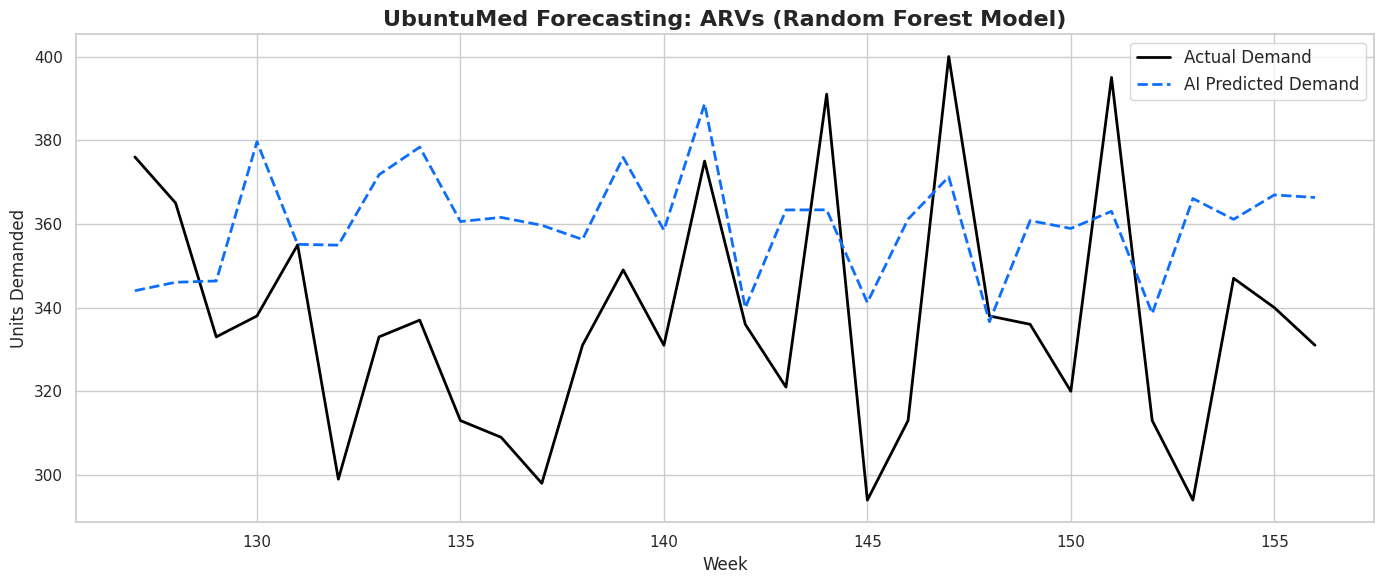

In [ ]:
# Create a test dataframe with predictions
test_df = df_clean[~train_mask].copy()
test_df['predictions'] = predictions

# Filter for ARVs
arvs_test = test_df[test_df['medicine'] == 'ARVs']

plt.figure(figsize=(14, 6))
plt.plot(arvs_test['week'], arvs_test['demand'], label='Actual Demand', color='black', linewidth=2)
plt.plot(arvs_test['week'], arvs_test['predictions'], label='AI Predicted Demand', color='#0d6efd', linestyle='--', linewidth=2)

plt.title('UbuntuMed Forecasting: ARVs (Random Forest Model)', fontsize=16, fontweight='bold')
plt.xlabel('Week', fontsize=12)
plt.ylabel('Units Demanded', fontsize=12)
plt.legend(fontsize=12)
plt.tight_layout()
plt.savefig('/content/drive/MyDrive/DATA/plots/1_forecast_actual_vs_predicted.png', dpi=300)
plt.show()

###Deep Learning Anomaly Detection

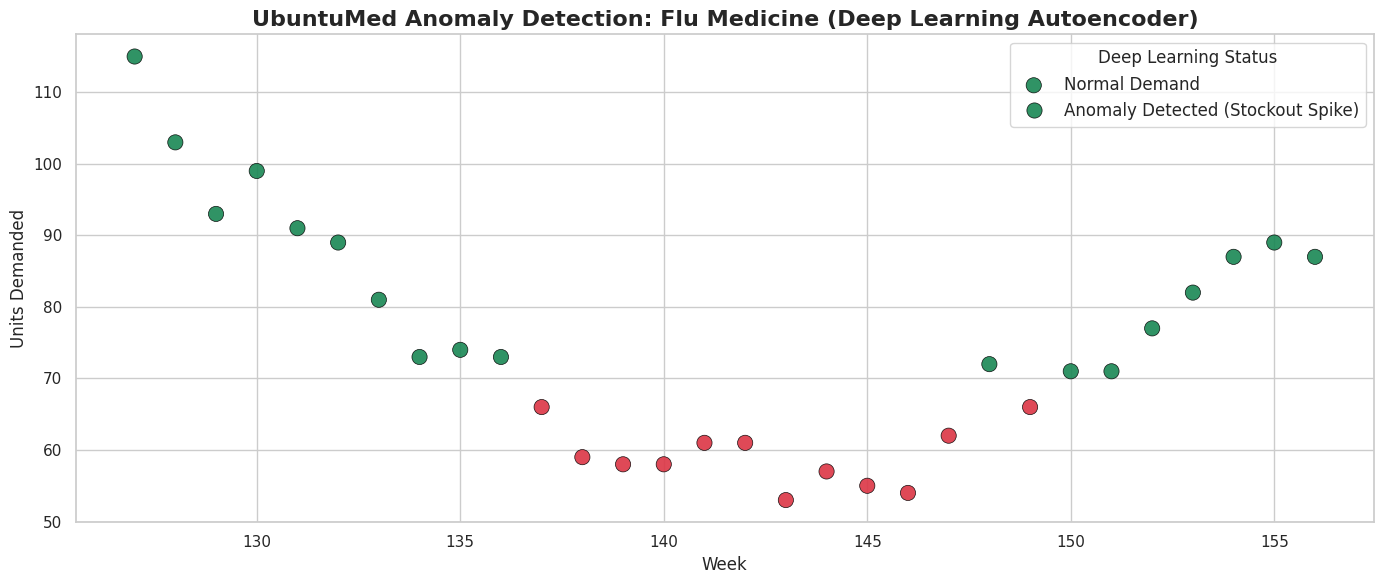

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Filter for Flu Medicine in the test set
flu_test = test_df[test_df['medicine'] == 'Flu Medicine'].copy()

# 2. Merge the deep learning anomaly column back in
flu_test = flu_test.merge(df[['medicine', 'week', 'dl_anomaly']], on=['medicine', 'week'], how='left')

# 3. Plotting
plt.figure(figsize=(14, 6))

# Explicitly set the colors to Green for 0, Red for 1
sns.scatterplot(data=flu_test, x='week', y='demand',
                hue='dl_anomaly', palette={0: '#198754', 1: '#dc3545'},
                s=120, alpha=0.9, edgecolor='black', linewidth=0.5)

# Fix the legend
plt.legend(title='Deep Learning Status', labels=['Normal Demand', 'Anomaly Detected (Stockout Spike)'], fontsize=12)

plt.title('UbuntuMed Anomaly Detection: Flu Medicine (Deep Learning Autoencoder)', fontsize=16, fontweight='bold')
plt.xlabel('Week', fontsize=12)
plt.ylabel('Units Demanded', fontsize=12)
plt.tight_layout()

# Save and show
plt.savefig('/content/drive/MyDrive/DATA/plots/2_anomaly_detection.png', dpi=300)
plt.show()

###Feature Importance (How the AI thinks)

/tmp/ipykernel_9182/2128476368.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=importances, y=features, palette='viridis')


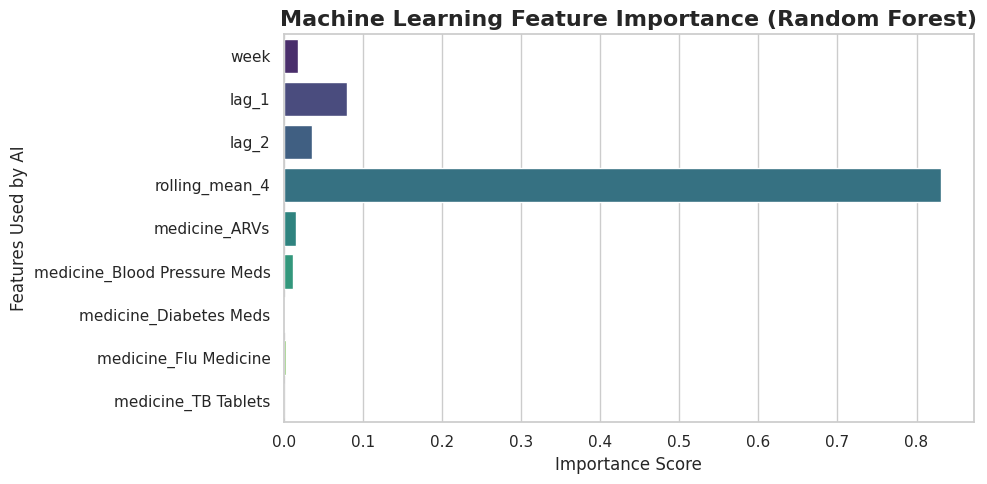

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))

# Get feature importances from the trained Random Forest
importances = forecast_model.feature_importances_

# Use X_train.columns instead of X.columns because we added One-Hot Encoding
features = X_train.columns

# Create a bar chart
sns.barplot(x=importances, y=features, hue=features, palette='viridis', dodge=False, legend=False)

plt.title('Machine Learning Feature Importance (Random Forest)', fontsize=16, fontweight='bold')
plt.xlabel('Importance Score', fontsize=12)
plt.ylabel('Features Used by AI', fontsize=12)
plt.tight_layout()

# Save and show
plt.savefig(f'{plot_dir}/3_feature_importance.png', dpi=300)
plt.show()

###Deep Learning Training Progress

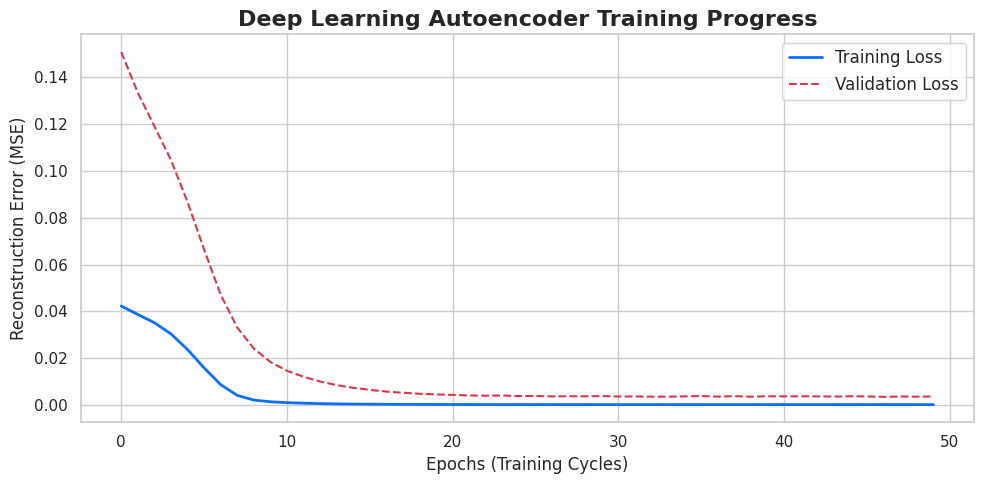

In [ ]:
import matplotlib.pyplot as plt

try:
    # Attempt to plot the training history if 'history' is defined in the namespace
    plt.figure(figsize=(10, 5))
    plt.plot(history.history['loss'], label='Training Loss', color='#0d6efd', linewidth=2)
    if 'val_loss' in history.history:
        plt.plot(history.history['val_loss'], label='Validation Loss', color='#dc3545', linestyle='--')

    plt.title('Deep Learning Autoencoder Training Progress', fontsize=16, fontweight='bold')
    plt.xlabel('Epochs (Training Cycles)', fontsize=12)
    plt.ylabel('Reconstruction Error (MSE)', fontsize=12)
    plt.legend(fontsize=12)
    plt.tight_layout()

    # Save and show
    plt.savefig(f'{plot_dir}/4_dl_training_loss.png', dpi=300)
    plt.show()
except NameError:
    print("Error: 'history' variable is not defined.")
    print("To fix this, please modify cell Wdyo_Y-ePdSf to capture the training progress:")
    print("Change:\n  autoencoder.fit(X_normal_scaled, X_normal_scaled, ...)")
    print("To:\n  history = autoencoder.fit(X_normal_scaled, X_normal_scaled, ...)")
    print("And then re-run that cell followed by this one!")

###Save All Models for the Backend

In [ ]:
import pickle
import os

os.makedirs('/content/drive/MyDrive/DATA/saved_models', exist_ok=True)

# Save Random Forest
with open('/content/drive/MyDrive/DATA/saved_models/forecast_model.pkl', 'wb') as f:
    pickle.dump(forecast_model, f)

# Save Isolation Forest
with open('/content/drive/MyDrive/DATA/saved_models/anomaly_model.pkl', 'wb') as f:
    pickle.dump(iso, f)

# Save Deep Learning Autoencoder
autoencoder.save('/content/drive/MyDrive/DATA/saved_models/dl_autoencoder.keras')

print(" ALL MODELS SAVED TO GOOGLE DRIVE!")
print("Check your DATA/saved_models folder in Google Drive.")

 ALL MODELS SAVED TO GOOGLE DRIVE!
Check your DATA/saved_models folder in Google Drive.
